# 02 · Forecasting day-ahead prices: results

**Question:** can a simple model beat a naive forecast?

**Setup** (see `src/omie/backtest.py`):
- On day D−1, forecast the 24 hourly prices of day D, using only prices up to D−1 and the calendar.
- Price: Portugal (`price_pt`), EUR/MWh.
- Test period: Jan 2024 to the latest day. **Walk-forward:** every month the models are
  retrained on all earlier data, then forecast that month.
- Models: `naive_24h` (same hour yesterday), `naive_168h` (same hour last week),
  `ridge` (linear regression), `lgbm` (gradient boosting, LightGBM).

This notebook reads the saved forecasts from `python -m omie.backtest`; re-run that command
first if the data has changed. Cells marked **✏️ Try** have a value you can change.

**Metrics:** MAE = average absolute error in EUR/MWh. RMSE = like MAE but penalises big misses
more. Relative MAE = model MAE ÷ `naive_24h` MAE; **below 1 means the model beats the naive
forecast**.

## 0 · Setup and a look at the forecasts

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from omie.backtest import MODELS, make_lgbm, metrics
from omie.config import DATA_PROCESSED, FIGURES
from omie.data import load_hourly
from omie.features import FEATURES, build_features, to_panel

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.precision", 2)

fc = pd.read_parquet(DATA_PROCESSED / "forecasts.parquet")
fc["datetime"] = fc["date"] + pd.to_timedelta(fc["hour"], unit="h")
fc["year"] = fc["date"].dt.year
fc["month"] = fc["date"].dt.to_period("M")
fc["weekday"] = fc["date"].dt.day_name().str[:3]

COLORS = {"naive_24h": "tab:gray", "naive_168h": "silver", "ridge": "tab:blue", "lgbm": "tab:orange"}
fc.head()

,date,hour,actual,naive_24h,naive_168h,ridge,lgbm,datetime,year,month,weekday
0,2024-01-01,0,63.33,18.21,75.00,45.83,83.22,2024-01-01 00:00:00,2024,2024-01,Mon
1,2024-01-01,1,50.09,5.00,69.03,36.95,70.35,2024-01-01 01:00:00,2024,2024-01,Mon
2,2024-01-01,2,47.50,4.00,59.90,33.53,61.48,2024-01-01 02:00:00,2024,2024-01,Mon
3,2024-01-01,3,43.50,0.31,61.16,30.56,55.56,2024-01-01 03:00:00,2024,2024-01,Mon
4,2024-01-01,4,42.50,0.00,49.30,28.28,51.89,2024-01-01 04:00:00,2024,2024-01,Mon


In [2]:
# Absolute error of each model, one column per model
err = fc[MODELS].sub(fc["actual"], axis=0).abs()
print(f"{len(fc):,} hourly forecasts from {fc['date'].min():%Y-%m-%d} to {fc['date'].max():%Y-%m-%d}")

25,176 hourly forecasts from 2024-01-01 to 2026-11-14


## 1 · Overall scores

In [3]:
overall = metrics(fc)
overall.stack(future_stack=True).droplevel(0).T  # rows = models, columns = metrics

,naive_24h,naive_168h,ridge,lgbm
MAE,19.66,28.89,19.04,17.92
RMSE,30.04,40.88,25.96,25.03
rel_MAE,1.00,1.47,0.97,0.91


In [4]:
metrics(fc, by="year")["rel_MAE"]

,naive_24h,naive_168h,ridge,lgbm
year,,,,
2024,1.0,1.50,0.93,0.93
2025,1.0,1.48,0.94,0.88
2026,1.0,1.44,1.04,0.94


## 2 · Scores by month

Relative MAE per month for the two trained models. Points below the line at 1 are months
where the model beat "same hour yesterday".

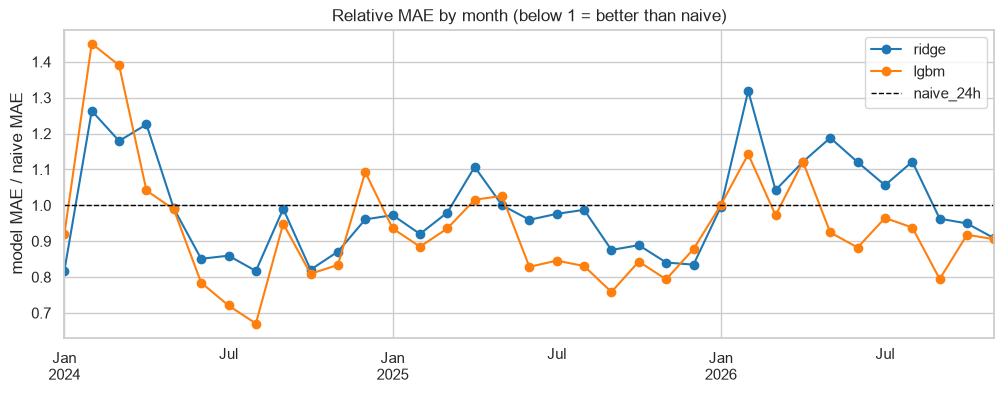

In [5]:
monthly = metrics(fc, by="month")["rel_MAE"]
ax = monthly[["ridge", "lgbm"]].plot(marker="o", color=[COLORS["ridge"], COLORS["lgbm"]])
ax.axhline(1, color="black", lw=1, ls="--", label="naive_24h")
ax.set(title="Relative MAE by month (below 1 = better than naive)", ylabel="model MAE / naive MAE",
       xlabel="")
ax.legend()
ax.figure.savefig(FIGURES / "forecast_monthly_rel_mae.png", dpi=150, bbox_inches="tight");

In [6]:
# Months where each model did best and worst
pd.DataFrame({
    "best month": monthly[["ridge", "lgbm"]].idxmin(),
    "rel_MAE (best)": monthly[["ridge", "lgbm"]].min(),
    "worst month": monthly[["ridge", "lgbm"]].idxmax(),
    "rel_MAE (worst)": monthly[["ridge", "lgbm"]].max(),
})

,best month,rel_MAE (best),worst month,rel_MAE (worst)
ridge,2024-08,0.82,2026-02,1.32
lgbm,2024-08,0.67,2024-02,1.45


## 3 · Forecast vs actual for one week

✏️ Try: change `WEEK_START` to any date in the test period (a Monday works best).
Ideas: a calm winter week (`"2024-01-15"`), a spring week with negative prices (`"2025-04-07"`),
or a recent week (`"2026-10-05"`).

MAE this week: {'naive_24h': 14.6, 'naive_168h': 13.2, 'ridge': 17.1, 'lgbm': 13.8}


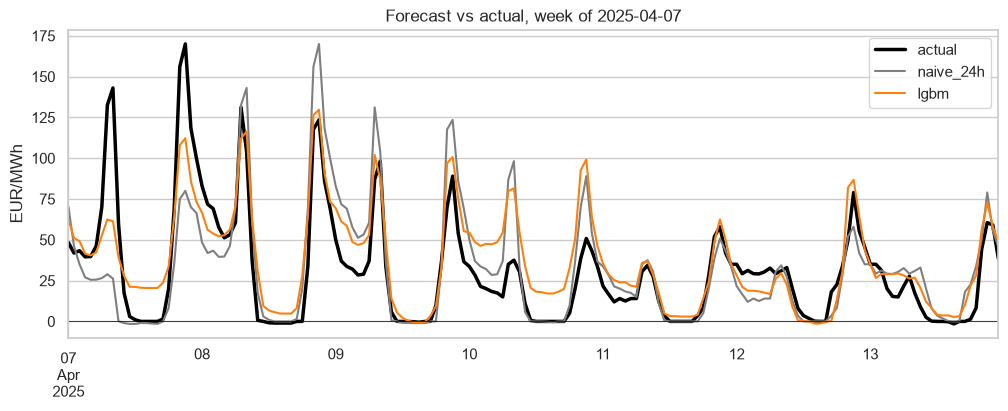

In [7]:
WEEK_START = "2025-04-07"
SHOW = ["naive_24h", "lgbm"]  # ✏️ Try: add "ridge" or "naive_168h"

start = pd.Timestamp(WEEK_START)
week = fc[(fc["date"] >= start) & (fc["date"] < start + pd.Timedelta(days=7))].set_index("datetime")

ax = week["actual"].plot(color="black", lw=2.5, label="actual")
for m in SHOW:
    week[m].plot(ax=ax, color=COLORS[m], lw=1.5, label=m)
ax.axhline(0, color="black", lw=0.5)
ax.set(title=f"Forecast vs actual, week of {WEEK_START}", ylabel="EUR/MWh", xlabel="")
ax.legend()
ax.figure.savefig(FIGURES / "forecast_example_week.png", dpi=150, bbox_inches="tight");
print("MAE this week:", week[MODELS].sub(week["actual"], axis=0).abs().mean().round(1).to_dict())

## 4 · Errors by hour of day

Which hours are hardest to forecast, and where do the models gain over the naive forecast?

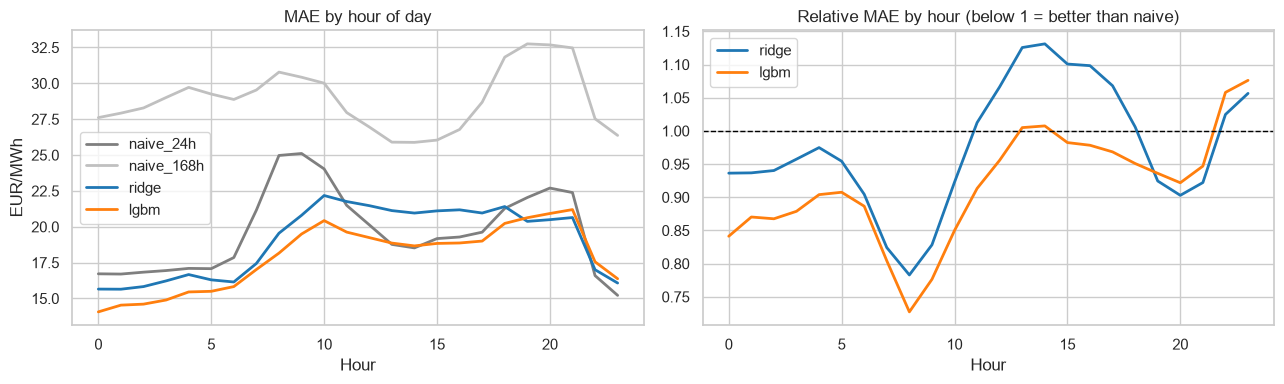

In [8]:
by_hour = err.groupby(fc["hour"]).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour.plot(ax=axes[0], color=[COLORS[m] for m in MODELS], lw=2)
axes[0].set(title="MAE by hour of day", xlabel="Hour", ylabel="EUR/MWh")
by_hour[["ridge", "lgbm"]].div(by_hour["naive_24h"], axis=0).plot(
    ax=axes[1], color=[COLORS["ridge"], COLORS["lgbm"]], lw=2)
axes[1].axhline(1, color="black", ls="--", lw=1)
axes[1].set(title="Relative MAE by hour (below 1 = better than naive)", xlabel="Hour")
plt.tight_layout()

## 5 · Errors by weekday

The naive forecast copies yesterday, so it should struggle on Mondays (copies Sunday) and
Saturdays (copies Friday). The trained models know the weekday.

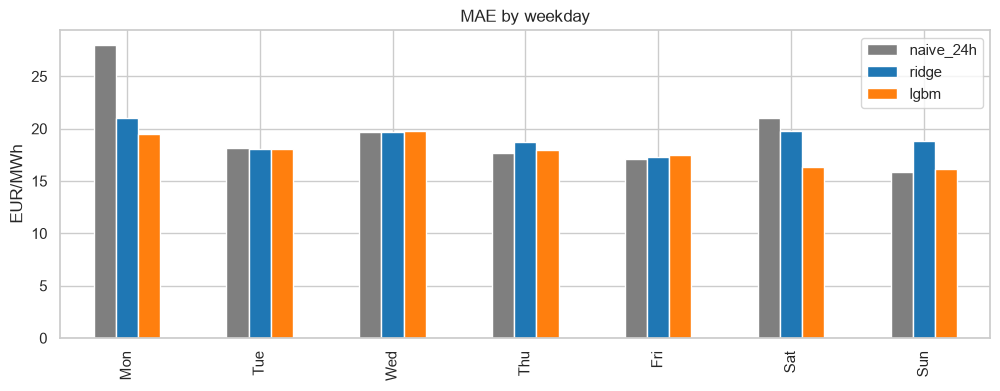

In [9]:
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = err.groupby(fc["weekday"]).mean().reindex(order)
ax = by_day[["naive_24h", "ridge", "lgbm"]].plot.bar(
    color=[COLORS[m] for m in ["naive_24h", "ridge", "lgbm"]])
ax.set(title="MAE by weekday", ylabel="EUR/MWh", xlabel="")
ax.figure.savefig(FIGURES / "forecast_error_by_weekday.png", dpi=150, bbox_inches="tight");

## 6 · The biggest misses

The 10 days with the largest average LightGBM error. What was the price doing on those days?

✏️ Try: change `MODEL` to see the worst days of another model.

In [10]:
MODEL = "lgbm"

daily = fc.assign(err=err[MODEL]).groupby("date").agg(
    model_mae=("err", "mean"),
    actual_mean=("actual", "mean"),
    actual_min=("actual", "min"),
    actual_max=("actual", "max"),
    forecast_mean=(MODEL, "mean"),
)
daily["change_vs_yesterday"] = daily["actual_mean"].diff()
worst = daily.nlargest(10, "model_mae")
worst

,model_mae,actual_mean,actual_min,actual_max,forecast_mean,change_vs_yesterday
date,,,,,,
2026-11-12,96.22,116.16,1.09,196.29,212.38,-94.78
2024-12-07,85.75,36.67,2.00,73.45,122.41,-81.99
2026-10-19,82.53,216.66,168.87,309.13,134.13,140.38
2024-11-24,79.00,10.71,3.32,41.54,89.71,-67.47
2026-10-08,77.49,106.90,0.00,198.80,184.39,-75.51
2026-09-28,62.50,198.10,150.32,265.67,135.60,84.42
2026-10-23,61.38,110.09,0.74,216.24,171.47,-45.54
2026-09-29,59.89,130.10,1.08,224.15,185.02,-68.00
2024-01-07,57.98,76.00,45.57,104.85,18.02,32.03


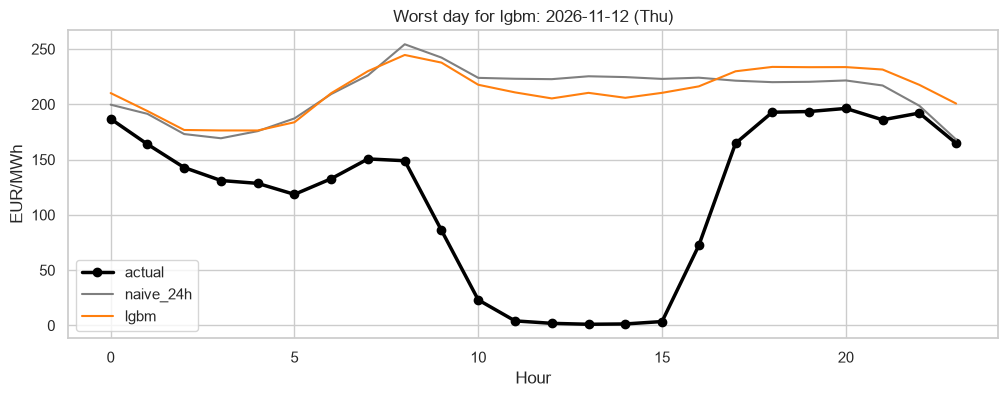

In [11]:
# Plot the single worst day
day = worst.index[0]
d = fc[fc["date"] == day].set_index("hour")
ax = d["actual"].plot(color="black", lw=2.5, marker="o", label="actual")
for m in ["naive_24h", MODEL]:
    d[m].plot(ax=ax, color=COLORS[m], lw=1.5, label=m)
ax.set(title=f"Worst day for {MODEL}: {day:%Y-%m-%d (%a)}", xlabel="Hour", ylabel="EUR/MWh")
ax.legend();

## 7 · Error vs price level

Are errors larger when prices are high? How well are negative prices forecast?

In [12]:
bins = [-float("inf"), 0, 25, 50, 100, 150, 200, float("inf")]
labels = ["≤ 0", "0–25", "25–50", "50–100", "100–150", "150–200", "> 200"]
level = pd.cut(fc["actual"], bins=bins, labels=labels)

table = err.groupby(level, observed=False).mean()
table.insert(0, "hours", level.value_counts().reindex(labels))
table

,hours,naive_24h,naive_168h,ridge,lgbm
actual,,,,,
≤ 0,1926,5.37,8.74,16.11,10.21
0–25,5108,16.74,27.74,23.93,20.84
25–50,3067,23.39,33.29,19.65,19.47
50–100,7248,22.85,30.50,16.12,16.95
100–150,5452,18.97,30.06,16.48,15.97
150–200,1603,21.90,31.81,21.91,21.65
> 200,772,30.00,39.69,31.13,26.76


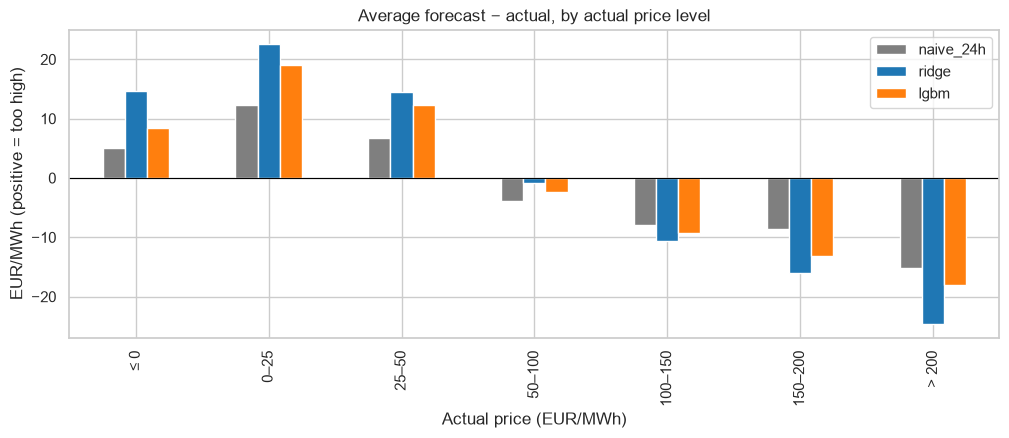

In [13]:
# Bias: does the model forecast too high or too low at each price level? (forecast − actual)
bias = fc[MODELS].sub(fc["actual"], axis=0).groupby(level, observed=False).mean()
ax = bias[["naive_24h", "ridge", "lgbm"]].plot.bar(
    color=[COLORS[m] for m in ["naive_24h", "ridge", "lgbm"]])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Average forecast − actual, by actual price level", xlabel="Actual price (EUR/MWh)",
       ylabel="EUR/MWh (positive = too high)");

## 8 · What LightGBM relies on

Retrain LightGBM once, on all data before the latest test month (as the backtest did), and look
at **feature importance (gain)**: how much each input reduced the error, summed over all trees.
Takes a few seconds.

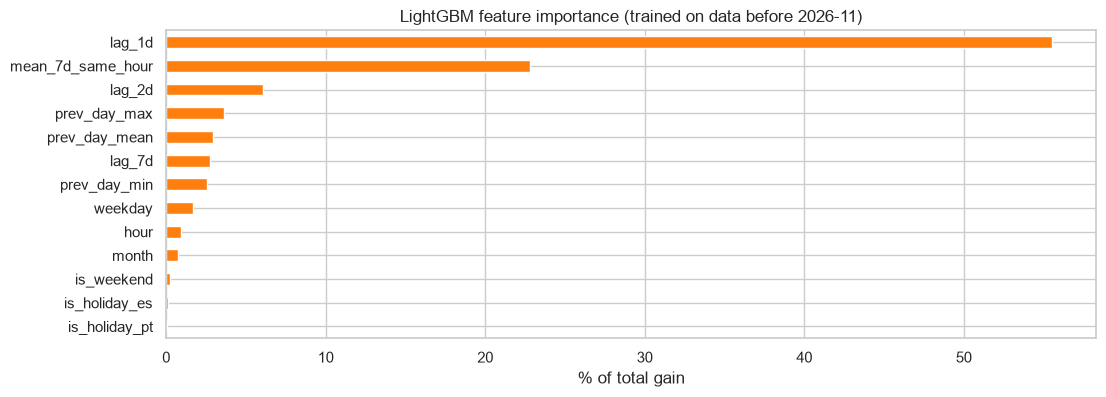

In [14]:
features = build_features(to_panel(load_hourly(), "price_pt"))
cutoff = fc["month"].max().start_time
train = features[features["date"] < cutoff]

model = make_lgbm().fit(train[FEATURES], train["price"])
importance = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
importance = (importance / importance.sum() * 100).sort_values()

ax = importance.plot.barh(color=COLORS["lgbm"])
ax.set(title=f"LightGBM feature importance (trained on data before {cutoff:%Y-%m})",
       xlabel="% of total gain")
ax.figure.savefig(FIGURES / "forecast_feature_importance.png", dpi=150, bbox_inches="tight");

## 8b · Does LightGBM need the calendar?

Section 8 suggests the calendar inputs (hour, weekday, month, weekend, holidays) hardly matter.
Feature importance only shows how often an input was useful *during training*, so here is a more
direct test: rerun the same walk-forward backtest with LightGBM **without** any calendar inputs and
compare errors by type of day. Takes about 20 seconds.

In [15]:
import holidays

from omie.backtest import monthly_splits

CALENDAR = ["hour", "weekday", "month", "is_weekend", "is_holiday_pt", "is_holiday_es"]
no_cal = [f for f in FEATURES if f not in CALENDAR]

preds = []
for start, tr_mask, te_mask in monthly_splits(features["date"], "2024-01"):
    tr, te = features[tr_mask], features[te_mask]
    if te.empty:
        continue
    m = make_lgbm().fit(tr[no_cal], tr["price"])
    preds.append(pd.Series(m.predict(te[no_cal]), index=te.index))
no_cal_pred = pd.concat(preds)

# Line the predictions up with fc (same dates and hours, same order)
test_rows = features[features["date"] >= "2024-01-01"][["date", "hour"]].assign(lgbm_no_calendar=no_cal_pred)
fc = fc.drop(columns="lgbm_no_calendar", errors="ignore")  # safe to re-run
fc = fc.merge(test_rows, on=["date", "hour"], how="left")

hol_pt = holidays.country_holidays("PT", years=range(2024, 2027))
day_type = fc["weekday"].map({"Mon": "Mon", "Sat": "Sat", "Sun": "Sun"}).fillna("Tue-Fri")
day_type[fc["date"].dt.date.map(lambda d: d in hol_pt)] = "PT holiday"

cols = ["naive_24h", "lgbm", "lgbm_no_calendar"]
cal_err = fc[cols].sub(fc["actual"], axis=0).abs()
cal_table = cal_err.groupby(day_type).mean()
cal_table.loc["ALL"] = cal_err.mean()
cal_table["days"] = fc.groupby(day_type)["date"].nunique()
cal_table.loc["ALL", "days"] = fc["date"].nunique()
cal_table.round(1)

,naive_24h,lgbm,lgbm_no_calendar,days
weekday,,,,
Mon,28.1,19.6,22.5,145.0
PT holiday,21.8,18.5,21.8,36.0
Sat,20.9,16.3,20.4,146.0
Sun,15.8,16.0,19.0,142.0
Tue-Fri,18.1,18.3,20.0,580.0
ALL,19.7,17.9,20.3,1049.0


## 8c · Level vs shape: where does the error come from?

Each day's error can be split into two parts:
- **level error:** getting the day's average price wrong;
- **shape error:** what is left once the level is right (the hour-by-hour profile).

If most of the error is in the level, better inputs about *tomorrow* (weather, demand, fuel prices)
would help more than a cleverer model.

In [16]:
rows = {}
for m in MODELS:
    e = fc[m] - fc["actual"]
    day_level_err = e.groupby(fc["date"]).transform("mean")
    rows[m] = {
        "MAE": e.abs().mean(),
        "avg |daily level error|": day_level_err.groupby(fc["date"]).first().abs().mean(),
        "MAE if daily level were known": (e - day_level_err).abs().mean(),
    }
pd.DataFrame(rows).T.round(1)

,MAE,avg |daily level error|,MAE if daily level were known
naive_24h,19.7,15.7,14.6
naive_168h,28.9,25.6,15.9
ridge,19.0,13.7,13.3
lgbm,17.9,14.2,11.7


## 8d · Is the improvement statistically significant? (Diebold–Mariano test)

A lower MAE could be luck. The **Diebold–Mariano (DM) test** checks whether one model's errors
are consistently smaller than another's. Following common practice in electricity price
forecasting, the 24 hourly loss differences of each day are averaged into one value per day
(the 24 prices of a day come from one auction, so their errors are not independent), and a
one-sided test asks: *is model A's error lower than model B's on average?*

- `DM statistic` > 0 means A has lower errors than B.
- `p-value` < 0.05 means the difference is statistically significant at the 5 % level.

In [17]:
from scipy import stats


def dm_test(a, b, loss="abs"):
    """One-sided DM test, H1: model `a` has lower expected loss than model `b`."""
    ea, eb = fc[a] - fc["actual"], fc[b] - fc["actual"]
    la, lb = (ea.abs(), eb.abs()) if loss == "abs" else (ea**2, eb**2)
    d = (lb - la).groupby(fc["date"]).mean()  # one value per day; > 0 when a is better
    stat = d.mean() / (d.std(ddof=1) / len(d) ** 0.5)
    return stat, stats.norm.sf(stat)


pairs = [("lgbm", "naive_24h"), ("ridge", "naive_24h"), ("lgbm", "ridge"), ("naive_24h", "naive_168h")]
dm = pd.DataFrame(
    [(f"{a} vs {b}", *dm_test(a, b)) for a, b in pairs],
    columns=["A vs B", "DM statistic", "p-value"],
).set_index("A vs B")
dm["significant (5 %)"] = dm["p-value"] < 0.05
dm.round(4)

,DM statistic,p-value,significant (5 %)
A vs B,,,
lgbm vs naive_24h,5.04,0.00e+00,True
ridge vs naive_24h,2.44,7.40e-03,True
lgbm vs ridge,5.34,0.00e+00,True
naive_24h vs naive_168h,13.15,0.00e+00,True


## 9 · Key takeaways

✏️ Write your own observations here after exploring: 4–6 short bullets. They will feed the
README, the docs and your CV entry.

- The LGBM model gives a modest improvement over the naive 24h forecast (about 9 % lower MAE). Most of the remaining error comes from tomorrow's price *level*, which depends on weather, demand and fuel prices that aren't in this dataset.
- The LGBM model performs slightly better than the ridge model
- Calendar features show low importance in the LGBM feature-importance chart but are essential: without them LGBM is worse than the naive forecast.